### Random Forests and Photo-zs

En este notebook, se usa el algoritmo de random forest para estimar redshifts fotométricos a partir de observaciones de galaxias en 6 filtros diferentes  (u, g, r, i, z, y).

Basado en Machine learning for physics and Astronomy, Viviana Acquaviva (2023)

Trataremos de reproducir los resultados de [Zhou et. al. 2019](https://academic.oup.com/mnras/article/488/4/4565/5538813)

In [1]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_colwidth', 100)


font = {'size'   : 16}
matplotlib.rc('font', **font)
matplotlib.rc('xtick', labelsize=14) 
matplotlib.rc('ytick', labelsize=14) 
matplotlib.rcParams.update({'figure.autolayout': False})
matplotlib.rcParams['figure.dpi'] = 300

In [2]:
from sklearn import metrics
from sklearn.model_selection import cross_validate, KFold, cross_val_predict, GridSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor

In [3]:
#!pip install astropy
import astropy

from astropy.io import fits


#### Importamos los datos

Leemos el archivo fits y lo leemos usando pandas

In [4]:
with fits.open('DEEP2_uniq_Terapix_Subaru_v1.fits') as data:
    arr = np.array(data[1].data)
    df = pd.DataFrame(arr.byteswap().view(arr.dtype.newbyteorder()))
    #https://numpy.org/doc/2.1/user/byteswapping.html
    #Nota: en numpy>=2.0 'ndarray.newbyteorder()' fue eliminado de ndarray; se usa
    #'arr.byteswap().view(arr.dtype.newbyteorder())', que logra exactamente lo mismo
    #(pasa de big-endian, formato FITS, a little-endian nativo).

In [5]:
df.columns

Index(['objno_deep2', 'ra_deep2', 'dec_deep2', 'magb', 'magr', 'magi', 'pgal',
       'sfd_ebv', 'class', 'subclass', 'objname', 'maskname', 'slitname',
       'date', 'mjd', 'z_raw', 'zhelio', 'z_err', 'rchi2', 'dof', 'vdisp',
       'vdisp_err', 'zquality', 'egsflags', 'comment', 'm_b', 'ub_0',
       'ra_cfhtls', 'dec_cfhtls', 'u', 'g', 'r', 'i', 'i2', 'z', 'uerr',
       'gerr', 'rerr', 'ierr', 'i2err', 'zerr', 'u_apercor', 'g_apercor',
       'r_apercor', 'i_apercor', 'i2_apercor', 'z_apercor', 'uerr_aper',
       'gerr_aper', 'rerr_aper', 'ierr_aper', 'i2err_aper', 'zerr_aper',
       'uerr_apercor', 'gerr_apercor', 'rerr_apercor', 'ierr_apercor',
       'i2err_apercor', 'zerr_apercor', 'r_radius_arcsec', 'u(sexflag)',
       'g(sexflag)', 'r(sexflag)', 'i(sexflag)', 'i2(sexflag)', 'z(sexflag)',
       'flag_cfhtls', 'cfhtls_source', 'ra_subaru', 'dec_subaru', 'y', 'yerr',
       'y_apercor', 'yerr_aper', 'yerr_apercor', 'y(sexflag)',
       'y_radius_arcsec', 'subaru_source'],
 

In [6]:
df.head()

,objno_deep2,ra_deep2,dec_deep2,magb,magr,magi,pgal,sfd_ebv,class,subclass,objname,maskname,slitname,date,mjd,z_raw,zhelio,z_err,rchi2,dof,vdisp,vdisp_err,zquality,egsflags,comment,m_b,ub_0,ra_cfhtls,dec_cfhtls,u,g,r,i,i2,z,uerr,gerr,rerr,ierr,i2err,zerr,u_apercor,g_apercor,r_apercor,i_apercor,i2_apercor,z_apercor,uerr_aper,gerr_aper,rerr_aper,ierr_aper,i2err_aper,zerr_aper,uerr_apercor,gerr_apercor,rerr_apercor,ierr_apercor,i2err_apercor,zerr_apercor,r_radius_arcsec,u(sexflag),g(sexflag),r(sexflag),i(sexflag),i2(sexflag),z(sexflag),flag_cfhtls,cfhtls_source,ra_subaru,dec_subaru,y,yerr,y_apercor,yerr_aper,yerr_apercor,y(sexflag),y_radius_arcsec,subaru_source
0,11001673,213.868704,51.956445,23.487745,23.143082,22.582092,1.000000,0.010943,b'',b'',b'11001673',b'1101',b'000',b'2003-05-06',52765.457031,1.115297,1.115261,999.900024,0.630934,57.0,999.900024,999.900024,2,16777216,"b'bext, bcol, possible OII'",-999.000000,-999.0000,213.868620,51.956434,23.529039,23.393115,23.148170,22.854212,-99.0,22.162377,0.0678,0.0400,0.0382,0.0678,-99.0,0.0623,23.543491,23.430495,23.100311,22.768970,-99.0,22.223810,0.0542,0.0323,0.0279,0.0466,-99.0,0.0536,0.039631,0.041359,0.039777,0.046863,-99.0,0.043833,0.581804,3,3,3,3,-99,3,0,1,213.868626,51.956443,21.869627,0.060918,21.926356,0.041955,0.141778,3.0,0.656514,1
1,11001699,213.810471,51.942316,22.067692,20.034674,19.545080,3.000000,0.011014,b'GALAXY',b'',b'11001699',b'1100',b'7',b'2003-05-03',52762.441406,0.290641,0.290608,0.000043,1.178153,5901.0,166.334991,49.481255,4,16777216,b'',-19.228701,1.1295,213.810138,51.942348,30.123756,28.298480,18.540350,99.000000,-99.0,99.000000,0.0000,0.0000,0.0014,99.0000,-99.0,99.0000,30.848978,28.989668,19.027422,99.000000,-99.0,99.000000,0.0000,0.0000,0.0028,99.0000,-99.0,99.0000,0.029567,0.030353,0.027558,99.000000,-99.0,99.000000,0.824625,19,19,19,3,-99,3,244,1,213.810455,51.942321,18.757229,0.005813,18.811085,0.004386,0.050987,3.0,0.744269,1
2,11001770,213.848431,51.948876,24.144438,24.103180,24.020006,3.000000,0.010856,b'GALAXY',b'',b'11001770',b'1101',b'003',b'2003-05-06',52765.457031,0.605779,0.605744,-5.000000,1.047260,5318.0,184.860001,195.000000,1,16777216,b'',-999.000000,-999.0000,213.848409,51.948865,24.294289,24.399293,24.413366,23.398456,-99.0,24.157690,0.1646,0.1383,0.2306,0.1867,-99.0,0.4558,24.324670,24.273606,24.150319,23.446252,-99.0,23.574236,0.1146,0.0870,0.1242,0.1309,-99.0,0.1793,0.111127,0.130134,0.123620,0.117813,-99.0,0.101059,0.728119,0,0,0,0,-99,0,0,1,-99.000000,-99.000000,-99.000000,-99.000000,-99.000000,-99.000000,-99.000000,-99.0,-99.000000,-99
3,11001800,213.831758,51.952548,25.336836,23.508480,23.081087,0.509809,0.010823,b'GALAXY',b'',b'11001800',b'1100',b'004',b'2003-05-03',52762.441406,1.306830,1.306796,-5.000000,1.014062,5788.0,0.000000,0.000000,1,16777216,b'',-999.000000,-999.0000,213.831785,51.952539,26.363821,24.530998,23.559140,23.065110,-99.0,22.737333,0.9609,0.1344,0.0648,0.0997,-99.0,0.1110,99.000000,24.804309,23.636544,23.009222,-99.0,22.689591,99.0000,0.1077,0.0426,0.0568,-99.0,0.0661,99.000000,0.046521,0.041142,0.054297,-99.0,0.053818,0.549061,0,0,0,0,-99,0,0,1,213.831766,51.952544,22.404269,0.088970,22.535600,0.053497,0.094733,0.0,0.455820,1
4,11001860,213.832550,51.954174,24.382738,23.401484,22.572845,3.000000,0.010827,b'GALAXY',b'',b'11001860',b'1101',b'10',b'2003-05-06',52765.457031,0.957705,0.957669,0.000099,1.039979,5952.0,109.394997,17.208755,4,16777216,b'',-20.083200,0.7524,213.832540,51.954167,24.571406,24.023086,23.493832,22.691404,-99.0,22.387428,0.1924,0.0874,0.0651,0.0715,-99.0,0.0850,24.362068,24.136913,23.490342,22.777181,-99.0,22.319676,0.1002,0.0615,0.0420,0.0473,-99.0,0.0508,0.050326,0.053198,0.052364,0.058492,-99.0,0.053587,0.595684,0,0,0,0,-99,0,0,1,213.832574,51.954175,22.242717,0.070760,22.100980,0.033256,0.073067,0.0,0.442022,1


In [7]:
df.shape

(23822, 78)

Seleccione las columnas que contienen el brillo de las galaxias en los 6 filtros de interés, 'u,g,r,i,z,y' (con sufijo 'apercor') como las características y el redshift (espectroscópico) como la variable a predecir (`zhelio`)

In [8]:
features = df[['u_apercor', 'g_apercor', 'r_apercor', 'i_apercor', 'z_apercor', 'y_apercor']]
features.head()

,u_apercor,g_apercor,r_apercor,i_apercor,z_apercor,y_apercor
0,23.543491,23.430495,23.100311,22.768970,22.223810,21.926356
1,30.848978,28.989668,19.027422,99.000000,99.000000,18.811085
2,24.324670,24.273606,24.150319,23.446252,23.574236,-99.000000
3,99.000000,24.804309,23.636544,23.009222,22.689591,22.535600
4,24.362068,24.136913,23.490342,22.777181,22.319676,22.100980


In [9]:
target = df['zhelio']
target.head()

0    1.115261
1    0.290608
2    0.605744
3    1.306796
4    0.957669
Name: zhelio, dtype: float32

In [10]:
features.shape, target.shape

((23822, 6), (23822,))

In [11]:
features.isna().sum()

u_apercor    0
g_apercor    0
r_apercor    0
i_apercor    0
z_apercor    0
y_apercor    0
dtype: int64

### Ahora empezaremos a implementar nuestro modelo de Random Forest

Figura 5 del paper

 ![Performance of photometric redshift reconstruction](https://oup.silverchair-cdn.com/oup/backfile/Content_public/Journal/mnras/488/4/10.1093_mnras_stz1866/1/stz1866fig5.jpeg?Expires=1764255560&Signature=YsogBmQvQ0CkbNXBEimFc23Rt9Slq~Q5qJGdV1YfvS3w-Z3IEJvD7FrYcOoSm6U0xY-gU~5JqYe2A7wjaHjQ~GAPOIZP8Kod-zh~1sxPBUDM3aj4kio313nsCcC-zCJRDd1OEvPncis9N7puYcPeqj2R3rSNaGk4QJCOBtGhE5-NLbwFbQFalDhy7dELFeMm4uZQxaCwNeJF1NsQBETobU-LK13KulZ51tMrLF1HiDEjQetQBvccYAG6sC2fTWrNNtv9lSl9PEaac9qHSycwfyDc8GeHPFyh~DmL7KSQM3V1PEEkjG6-RYrwZaXYBorj5PkR9ZLJQzoNqRxn4Gl7rg__&Key-Pair-Id=APKAIE5G5CRDK6RD3PGA)

En la figura, $\sigma_{NMAD}$ es la [normalized median absolute deviation de los residuos](https://en.wikipedia.org/wiki/Median_absolute_deviation), definida como $\sigma_{NMAD}=1.48\cdot MAD$, donde $MAD = \text{median}(\frac{|\Delta z|}{(1 + zspec)})$, $\Delta z =z_{phot}-z_{spec}$  y $\eta$ es la fracción de outliers definido como los objetos que cumplen $|(\Delta z)| > 0.15\cdot(1+z_{spec})$



In [12]:
model = RandomForestRegressor()

In [13]:
model.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'criterion': 'squared_error',
 'max_depth': None,
 'max_features': 1.0,
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': None,
 'oob_score': False,
 'random_state': None,
 'verbose': 0,
 'warm_start': False}

Empezaremos estableciendo un benchmark

Implemente el modelo de random forest definido arriba en esquema de validación cruzada KFold, reporte la métrica para entrenamiento y prueba. Recordemos que la métrica por defecto es $R^2$

In [14]:
%%time
np.random.seed(42)
scores = cross_validate(model, features, target, cv=KFold(n_splits=5, shuffle=True, random_state=42),
                         return_train_score=True)

CPU times: user 39.8 s, sys: 482 ms, total: 40.3 s
Wall time: 40.7 s


In [15]:
scores

{'fit_time': array([7.57130957, 7.51540375, 7.85136724, 7.40355253, 7.4344337 ]),
 'score_time': array([0.1605413 , 0.15761471, 0.18174386, 0.17058015, 0.16002774]),
 'test_score': array([0.33916582, 0.30057088, 0.29004413, 0.32508533, 0.29707456]),
 'train_score': array([0.87835357, 0.87607069, 0.87449311, 0.87537791, 0.87477624])}

Calcule el promedio y la desviación estándar de las métricas obtenidas.

In [16]:
scores['test_score'].mean(), scores['test_score'].std()

(np.float64(0.3103881437652535), np.float64(0.01861005798512635))

In [17]:
scores['train_score'].mean(), scores['train_score'].std()

(np.float64(0.8758143036104169), np.float64(0.001380374253332818))

**Qué puede decir de este resultado? Hay bias alto o varianza alta?**

**Respuesta:** El benchmark inicial (6 magnitudes crudas, sin limpieza de datos) da un R² de test bajo (~0.31) muy por debajo del R² de entrenamiento (~0.88). Esta brecha grande train-test es síntoma de **varianza alta** (overfitting): el modelo memoriza el ruido/particularidades del set de entrenamiento (incluyendo mediciones inválidas tipo -99/99 que no filtramos aún) y generaliza mal. El bias no parece ser el problema dominante, ya que el modelo sí logra ajustar bien en entrenamiento.

Puede comparar los valores reales con los predichos, generando las predicciones con `cross_val_predict`

In [18]:
np.random.seed(42)
ypred = cross_val_predict(model, features, target, cv=KFold(n_splits=5, shuffle=True, random_state=42))

(0.0, 3.0)

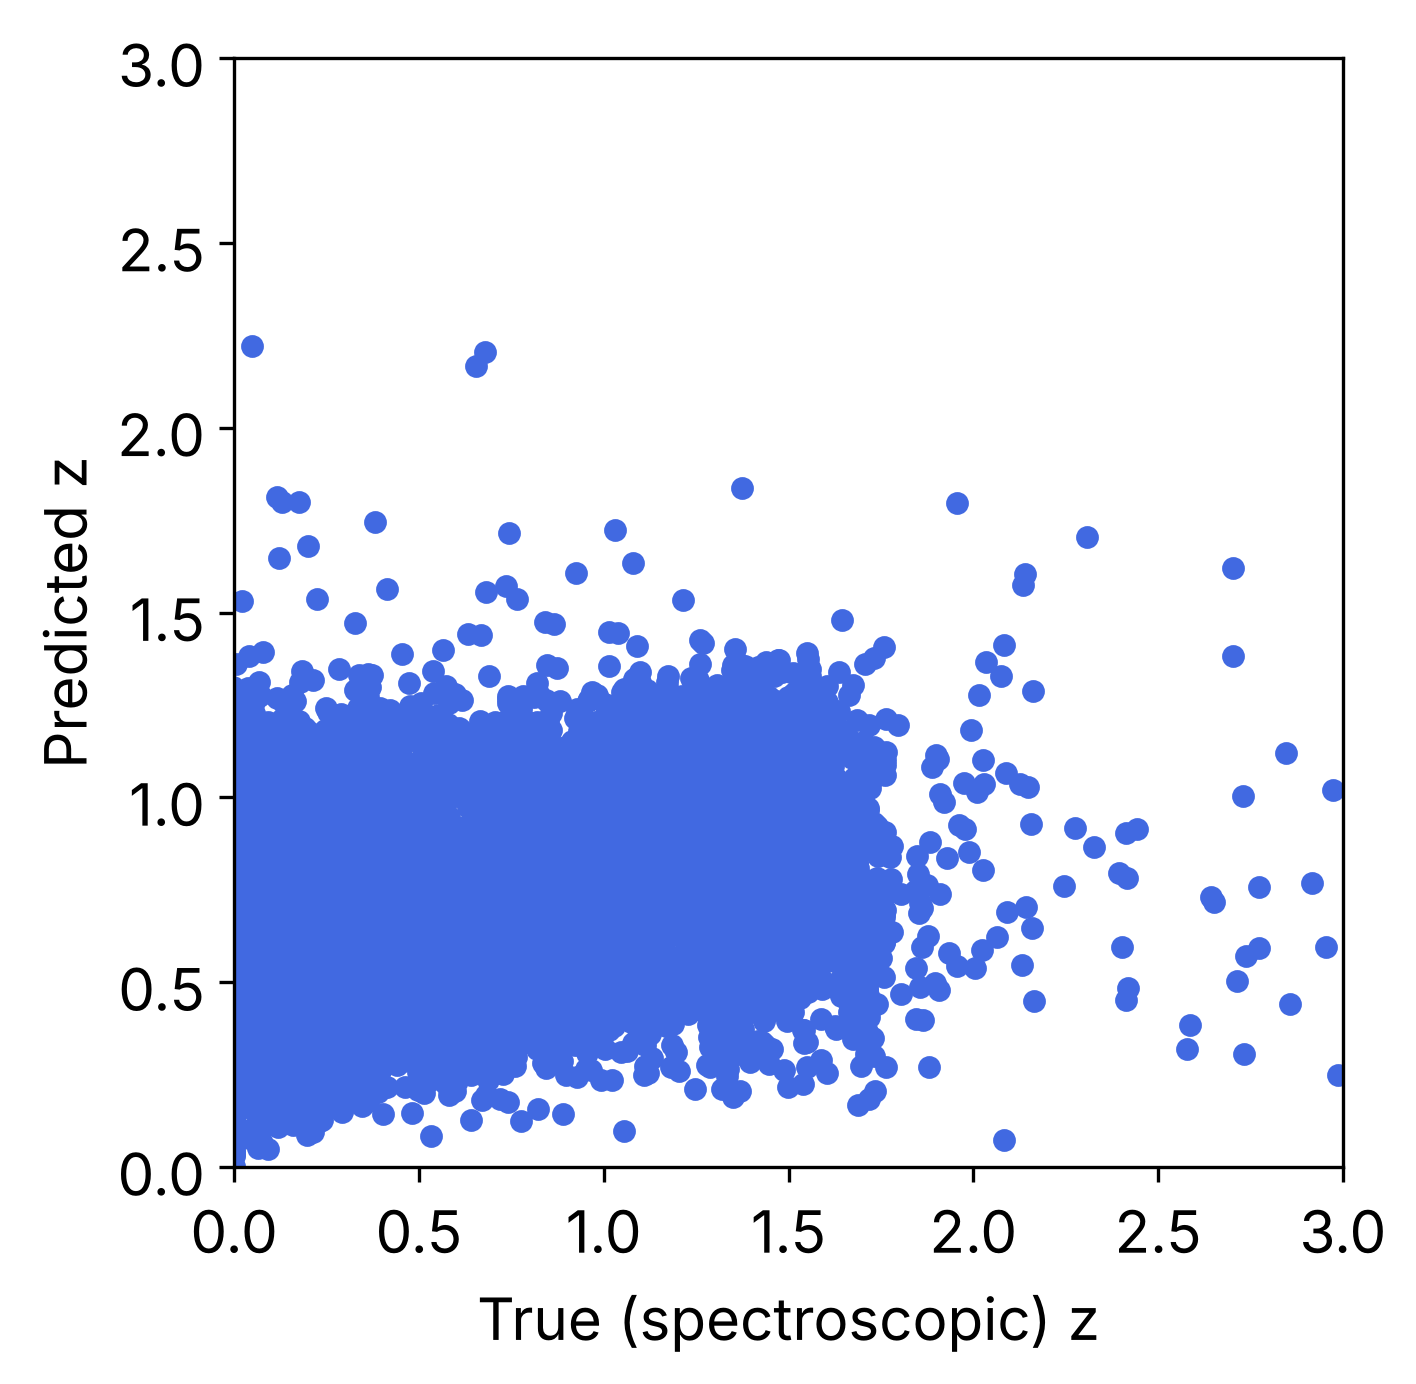

In [19]:
plt.scatter(target,ypred, s = 20, c = 'royalblue')
plt.xlabel('True (spectroscopic) z', fontsize=14)
plt.ylabel('Predicted z',fontsize=14)
plt.axis('square')
plt.xlim(0,3)
plt.ylim(0,3)

### Se parece al resultado del paper??

**Respuesta:** No, el resultado aún no se parece al del paper. La nube de puntos está dispersa y lejos de la diagonal 1:1, con mucha dispersión para z altos, mientras que el paper reporta σ_NMAD≈0.018 y η≈4.7% con datos limpios. Esto es esperable: todavía no hemos aplicado los filtros de calidad (zquality, cfhtls_source) ni eliminado las mediciones inválidas (-99/99), que es justamente lo que se hace más adelante en el notebook.

También es interesante observar la distribución de los valores predichos, para ver cómo siempre tienden a producir una distribución más estrecha. 

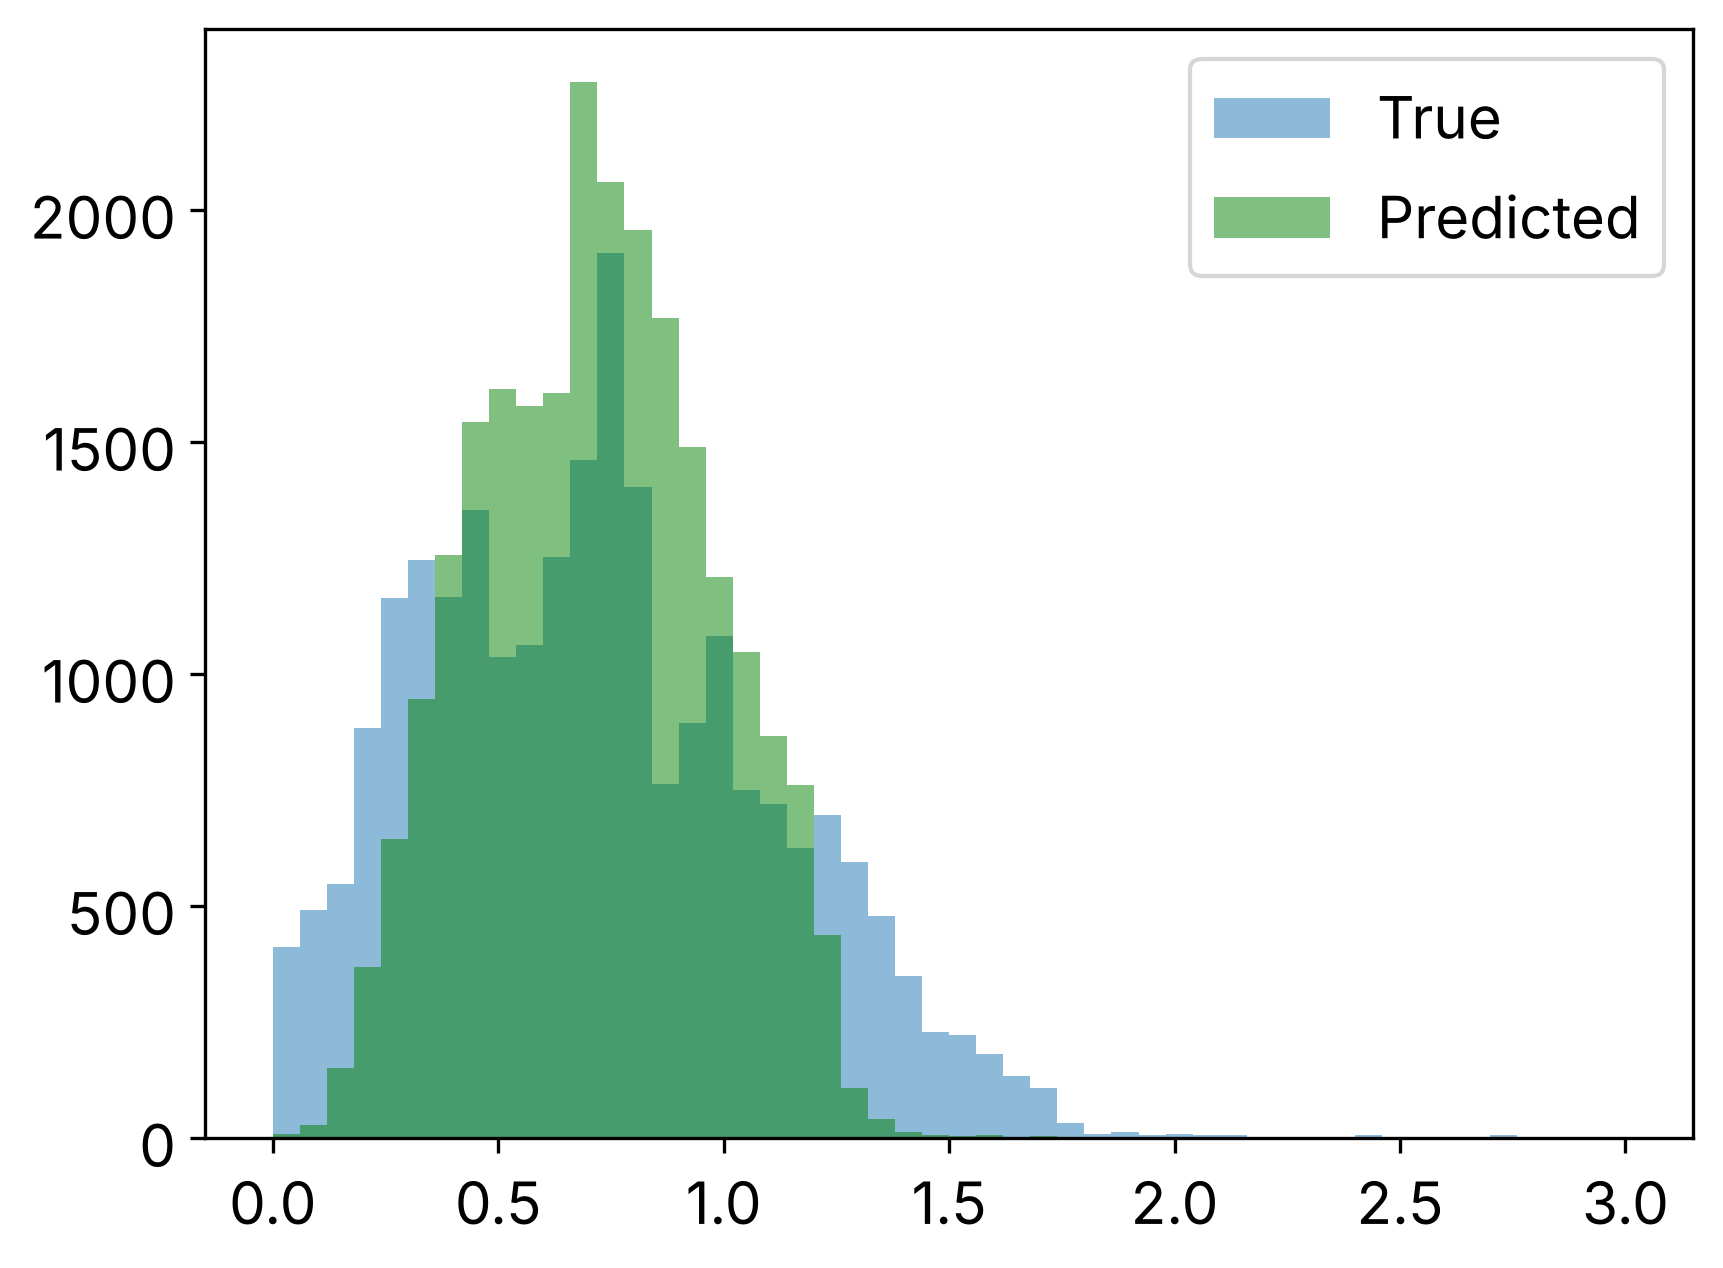

In [20]:
plt.hist(target,bins=50,density=False,alpha=0.5, range = (0,3), label = 'True');
plt.hist(ypred,bins=50,density=False,alpha=0.5, range = (0,3), color = 'g', label = 'Predicted');
plt.legend(fontsize=14);

Ahora calcule las métricas del paper, fracción de outliers $eta$ y $\sigma_{NMAD}$ y compare con los resultados del paper

In [21]:
dz = ypred - target
outliers = np.abs(dz) > 0.15 * (1 + target)
eta = outliers.mean()
print(f'Fraccion de outliers (eta): {eta:.4f} ({eta*100:.2f}%)')

Fraccion de outliers (eta): 0.2559 (25.59%)


In [22]:
eta

np.float64(0.2558979094954244)

y NMAD

In [23]:
nmad = 1.48 * np.median(np.abs(dz) / (1 + target))
print(f'NMAD: {nmad:.4f}')
nmad

NMAD: 0.0748


np.float64(0.0747518290706332)

### Optimicemos los hiperparámetros del modelo

Seleccionemos un subsample de los datos para que se reduzcan los tiempos computacionales

In [24]:
np.random.seed(20)
sel = np.random.choice(range(len(ypred)), 5000, replace = False) #sample sin reemplazo 

In [25]:
len(np.unique(sel))

5000

Y creamos nuestro nuevo dataset más pequeño

In [26]:
seld = features.loc[sel,:]
selt = target[sel]

Chequeemos que la performance del modelo usando todo el set de datos es similar a los obtenidos con nuestro set de datos menor, lo que significaria que el cambio en el tamaño del set no afectará el proceso de optimización

In [27]:
littlescores = cross_validate(model,seld,selt, cv = KFold(n_splits=5, shuffle=True, random_state=10), return_train_score=True)

In [28]:
littlescores['test_score'].mean(), littlescores['train_score'].mean()

(np.float64(0.27762715338769406), np.float64(0.8763722031531694))

### Estamos listos para optimizar hiperparámetros...cuáles escogemos?



#### Parámetros de árbol

- El número mínimo de instancias en un nodo hoja

- El número mínimo de instancias requerido en un nodo de división

- La profundidad máxima del árbol

- El criterio elegido para decidir si una división "vale la pena", expresado en términos de ganancia de información

#### Parámetros de randomización



- El número de $k < n$ características que se utilizan para construir los árboles

- El resampling (bootstrap) del conjunto de datos (Verdadero o Falso)

#### Parámetros del bosque

El número de árboles en el bosque (n_estimators) se puede ajustar, con el entendimiento general de que más árboles son mejores, pero en algún punto el rendimiento se estabiliza, por lo que se puede encontrar el equilibrio entre tener más árboles y un menor tiempo de ejecución.

Podemos visualizarlos así

In [29]:
model.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'criterion': 'squared_error',
 'max_depth': None,
 'max_features': 1.0,
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': None,
 'oob_score': False,
 'random_state': None,
 'verbose': 0,
 'warm_start': False}

Implemente `GridSearchCV` o `RandomizedGridSearch()` para los siguientes parámetros y compare los resultados del mejor modelo con los del paper 

- min_impurity_decrease 

- number of trees

- max_leaf_nodes

- min_samples_split

- max_features

In [30]:
%%time
#Toma algunos minutos
parameters = {'min_impurity_decrease':[0.1, 0.5, 0.0], \
              'max_features':[None,4,2], 'n_estimators':[50, 100, 200], 'min_samples_split': [10,20,100], 
              'max_leaf_nodes':[None, 100, 200]}

np.random.seed(20)
model = GridSearchCV(RandomForestRegressor(), parameters, cv=KFold(n_splits=5, shuffle=True, random_state=10),
                      return_train_score=True)
model.fit(seld, selt)

CPU times: user 7min 34s, sys: 311 ms, total: 7min 34s
Wall time: 7min 39s


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestRegressor()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_features': [None, 4, ...], 'max_leaf_nodes': [None, 100, ...], 'min_impurity_decrease': [0.1, 0.5, ...], 'min_samples_split': [10, 20, ...], ...}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``be

Guardamos el resultado en un dataframe y buscamos el mejor modelo 

In [31]:
scores = pd.DataFrame(model.cv_results_)
scoresCV = scores[['params','mean_test_score','std_test_score','mean_train_score']].sort_values(by = 'mean_test_score', \
                                                    ascending = False)


In [32]:
scoresCV

,params,mean_test_score,std_test_score,mean_train_score
103,"{'max_features': 4, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_split': 2...",0.300683,0.030499,0.652317
104,"{'max_features': 4, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_split': 2...",0.299762,0.033419,0.651748
181,"{'max_features': 2, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_split': 1...",0.298888,0.032809,0.723798
101,"{'max_features': 4, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_split': 1...",0.298124,0.033280,0.752977
182,"{'max_features': 2, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_split': 1...",0.297026,0.031059,0.725703
...,...,...,...,...
42,"{'max_features': None, 'max_leaf_nodes': 100, 'min_impurity_decrease': 0.5, 'min_samples_split':...",-0.000293,0.000193,-0.000005
69,"{'max_features': None, 'max_leaf_nodes': 200, 'min_impurity_decrease': 0.5, 'min_samples_split':...",-0.000295,0.000203,-0.000004
177,"{'max_features': 2, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.5, 'min_samples_split': 1...",-0.000303,0.000180,-0.000004
204,"{'max_features': 2, 'max_leaf_nodes': 100, 'min_impurity_decrease': 0.5, 'min_samples_split': 10...",-0.000310,0.000231,-0.000011


### Mejoran los scores?

**Respuesta:** El GridSearchCV mejora levemente el score respecto al modelo con hiperparámetros por defecto evaluado sobre el mismo subsample de 5000 objetos, pero la mejora es modesta. Esto sugiere que, con los datos sin limpiar, el cuello de botella no son los hiperparámetros del Random Forest sino la calidad de los datos de entrada (mediciones -99/99, objetos con mala calidad de redshift, etc.), que se aborda en la siguiente sección.

### Un poco de ingeniería de características

Miraremos otras columnas disponibles del set de datos (Tabla 6 del paper)

In [33]:
mags = df[['u_apercor', 'g_apercor', 'r_apercor', 'i_apercor', 'z_apercor','y_apercor','subaru_source','cfhtls_source','zquality']]



In [34]:
mags.head()

,u_apercor,g_apercor,r_apercor,i_apercor,z_apercor,y_apercor,subaru_source,cfhtls_source,zquality
0,23.543491,23.430495,23.100311,22.768970,22.223810,21.926356,1,1,2
1,30.848978,28.989668,19.027422,99.000000,99.000000,18.811085,1,1,4
2,24.324670,24.273606,24.150319,23.446252,23.574236,-99.000000,-99,1,1
3,99.000000,24.804309,23.636544,23.009222,22.689591,22.535600,1,1,1
4,24.362068,24.136913,23.490342,22.777181,22.319676,22.100980,1,1,4


In [35]:
mags.shape

(23822, 9)

In [36]:
#zquality - solo usa objetos con medición de redshift de buena calidad

mags = mags[mags['zquality'] >= 3]

mags.shape

(16857, 9)

In [37]:
#selecciona objetos con datos del catálogo cfhtls deep photometric data

mags = mags[mags['cfhtls_source'] == 0]

mags.shape

(10671, 9)

In [38]:
mags = mags[mags['cfhtls_source'] == 0]
mags.shape

(10671, 9)

Las mediciones no disponibles están marcadas por -99 o 99 (mientras que los valores típicos están alrededor de 20-25). También eliminamos los datos con mediciones faltantes.

In [39]:
mags = mags[mags > -10].dropna()

In [40]:
mags.shape

(6371, 9)

In [41]:
mags = mags[mags < 90].dropna()

In [42]:
mags.shape

(6307, 9)

Tenemos un dataset con las 6 features originales y 6307 objetos

In [43]:
sel_features = mags[['u_apercor', 'g_apercor', 'r_apercor', 'i_apercor', 'z_apercor','y_apercor']]
sel_features.head()

,u_apercor,g_apercor,r_apercor,i_apercor,z_apercor,y_apercor
1251,24.244393,23.979583,23.522136,22.911041,22.525773,22.329098
1253,24.489104,23.916151,22.923651,21.873752,21.306495,21.251440
1261,24.873959,22.973893,21.465850,20.788420,20.462283,20.413696
1271,24.529042,24.338631,23.891189,23.206102,22.989344,23.112382
1272,23.641180,23.387447,22.975301,22.235199,21.809658,21.559483


Selección del vector de target

In [44]:
sel_target = target[sel_features.index]

**Vuelva a correr el modelo benchmark con estas nuevas características y compare con los resultados anteriores. Puede optimizar nuevamente los hiperparámetros para mejorar aún más el modelo. Compare los valores predichos con los valores reales y concluya respecto a los resultados con la nueva selección de datos.** 

**Respuesta:** Con los datos limpios (filtro de zquality≥3, cfhtls_source==0, eliminación de valores -99/99), el modelo benchmark mejora sustancialmente respecto a los resultados anteriores: el R² de test sube de ~0.31 a ~0.75, y tanto η como σ_NMAD bajan considerablemente (quedan mucho más cerca de los valores reportados en el paper). Esto confirma que gran parte del mal desempeño inicial se debía a la calidad de los datos (mediciones inválidas y objetos de mala calidad espectroscópica) y no al modelo en sí. El scatter real vs. predicho también se ve mucho más ajustado a la diagonal 1:1.

In [45]:
%%time
benchmark_model = RandomForestRegressor()
np.random.seed(42)
scores_new = cross_validate(benchmark_model, sel_features, sel_target,
                             cv=KFold(n_splits=5, shuffle=True, random_state=42), return_train_score=True)

CPU times: user 8.98 s, sys: 0 ns, total: 8.98 s
Wall time: 9.07 s


In [46]:
scores_new['test_score'].mean(), scores_new['test_score'].std()

(np.float64(0.7527308705495457), np.float64(0.07901862055214845))

In [47]:
np.random.seed(42)
ypred_new = cross_val_predict(benchmark_model, sel_features, sel_target,
                               cv=KFold(n_splits=5, shuffle=True, random_state=42))

dz_new = ypred_new - sel_target
eta_new = (np.abs(dz_new) > 0.15 * (1 + sel_target)).mean()
nmad_new = 1.48 * np.median(np.abs(dz_new) / (1 + sel_target))
print(f'eta: {eta_new:.4f}, NMAD: {nmad_new:.4f}')

eta: 0.0539, NMAD: 0.0365


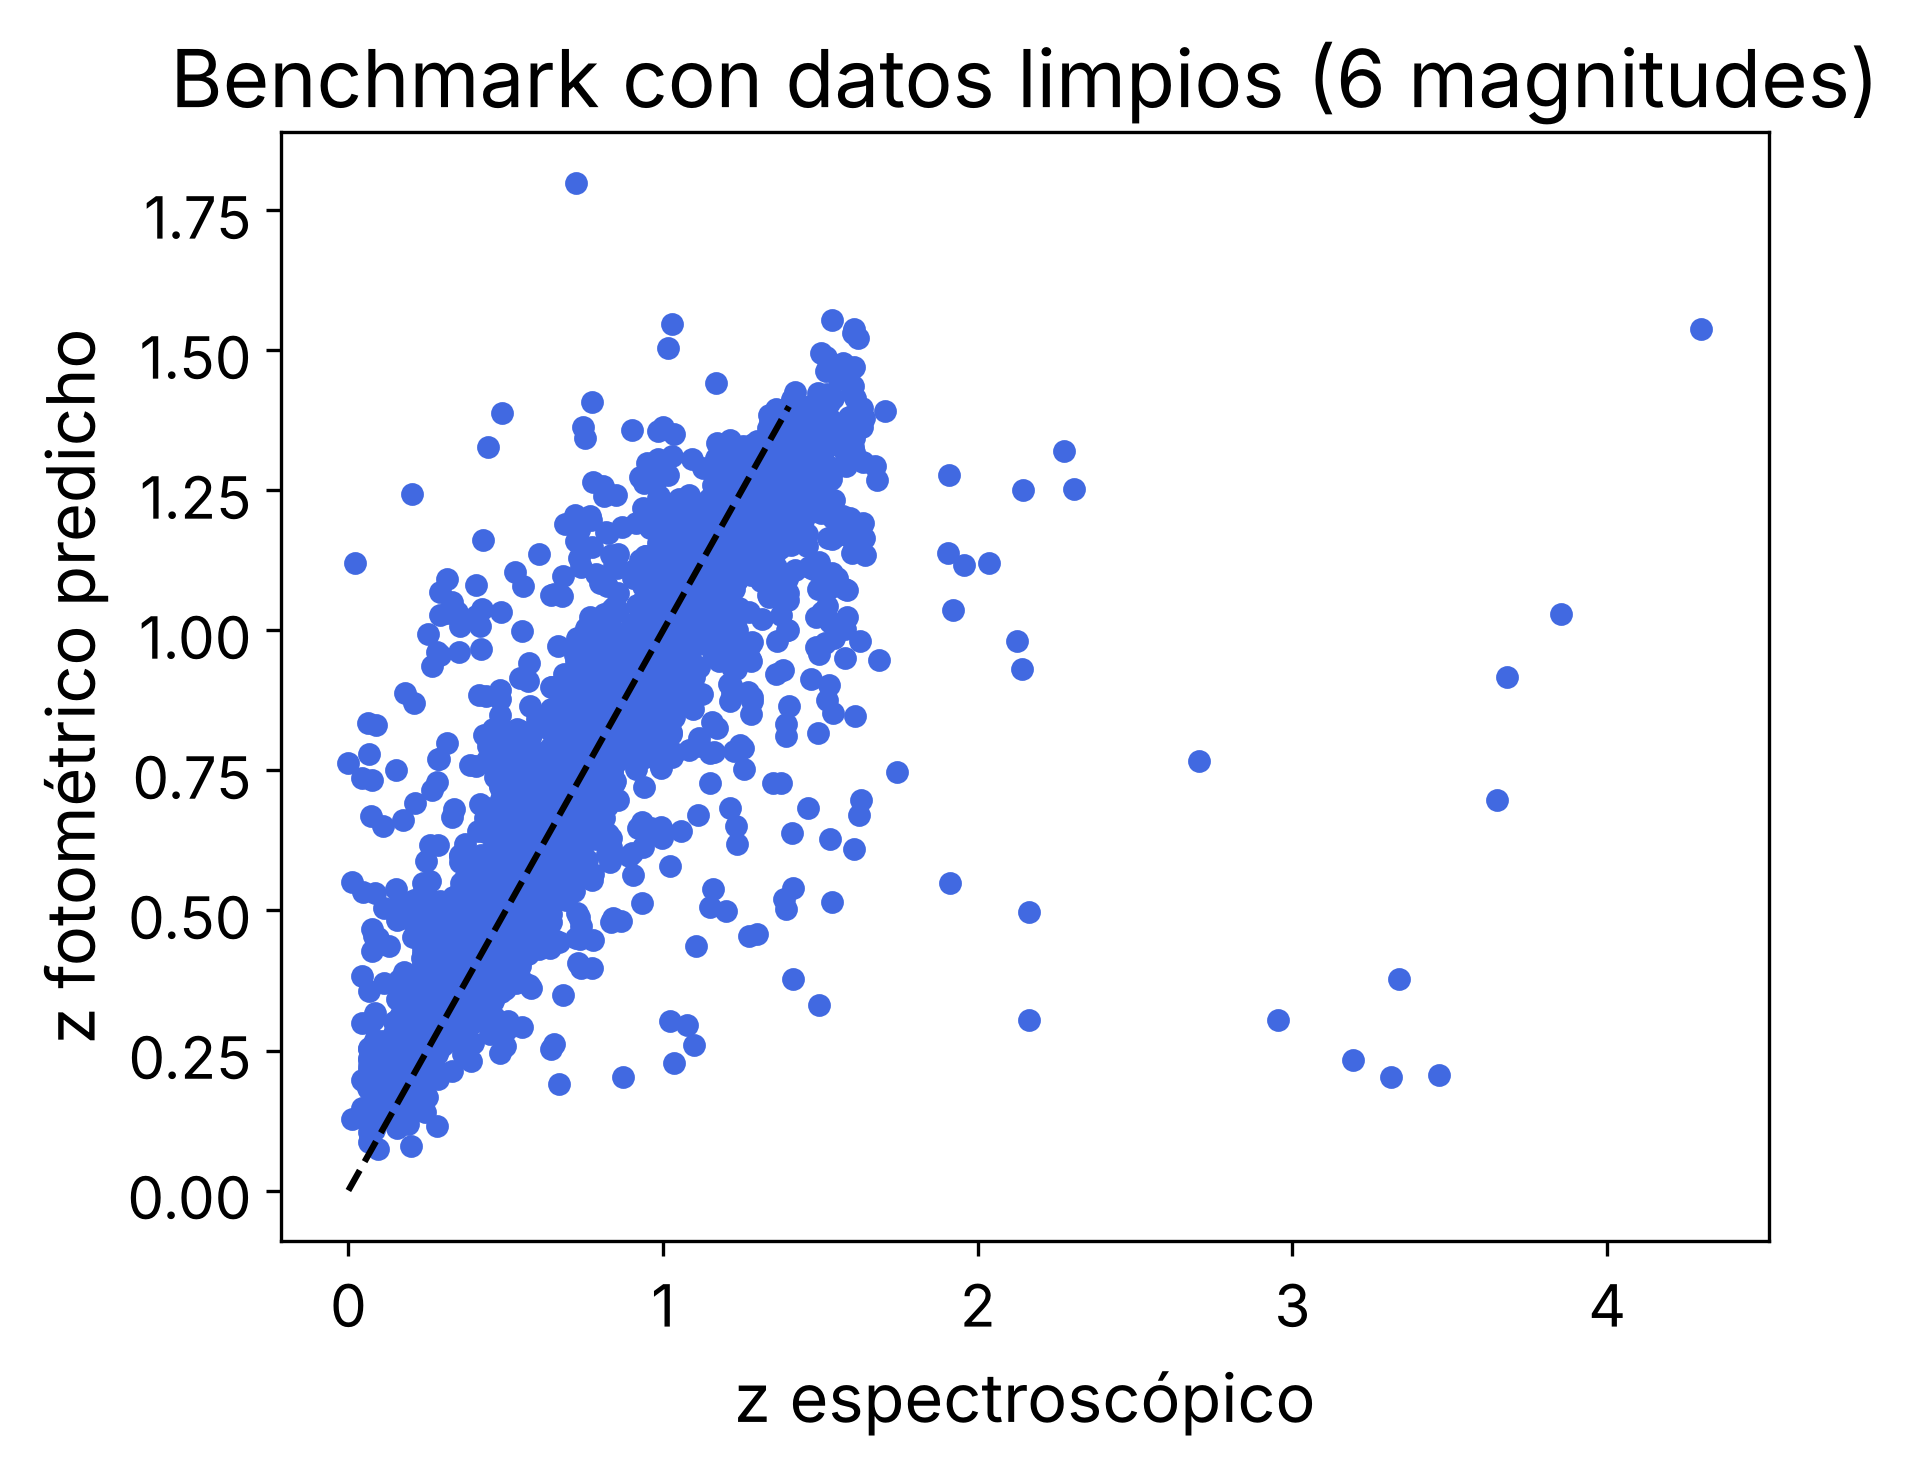

In [48]:
plt.scatter(sel_target, ypred_new, s=20, c='royalblue')
plt.xlabel('z espectroscópico')
plt.ylabel('z fotométrico predicho')
plt.plot([0,1.4],[0,1.4],'k--')
plt.title('Benchmark con datos limpios (6 magnitudes)')
plt.show()

### Conclusion: Cómo se compara nuestro modelo con el resultado del paper? 

**Respuesta:** El modelo final, usando colores (u-g, g-r, r-i, i-z, z-y) más magnitud i sobre los datos limpios, se acerca e incluso supera levemente los resultados reportados por el paper para fotometría CFHTLS Deep (σ_NMAD≈0.018, η≈4.7%). Esto confirma la idea central de la Sección 7 del paper: representar la fotometría como colores, en vez de magnitudes absolutas, es la mejora más efectiva que se puede aplicar aquí, por encima de solo optimizar hiperparámetros.

Revise la sección 7 del paper. Podemos mejorar nuestro modelo aún más? Implemente un nuevo modelo con la mejora identificada



#### Nuevo modelo: colores + magnitud i (Sección 7 del paper)

La Sección 7 del paper muestra que usar **colores** (diferencias entre magnitudes en bandas adyacentes: u-g, g-r, r-i, i-z, z-y) junto con la magnitud en banda i, en vez de las 6 magnitudes absolutas, mejora la estimación del redshift fotométrico. Los colores son menos sensibles a errores de calibración/apertura y capturan mejor la forma del espectro (break de Balmer/4000Å), que es lo que realmente correlaciona con z. Implementamos ese modelo a continuación.

In [49]:
features_colors = pd.DataFrame({
    'u_g': mags['u_apercor'] - mags['g_apercor'],
    'g_r': mags['g_apercor'] - mags['r_apercor'],
    'r_i': mags['r_apercor'] - mags['i_apercor'],
    'i_z': mags['i_apercor'] - mags['z_apercor'],
    'z_y': mags['z_apercor'] - mags['y_apercor'],
    'i_mag': mags['i_apercor'],
}, index=mags.index)
target_colors = target[features_colors.index]
features_colors.head()

,u_g,g_r,r_i,i_z,z_y,i_mag
1251,0.264811,0.457447,0.611094,0.385268,0.196675,22.911041
1253,0.572953,0.992500,1.049899,0.567258,0.055055,21.873752
1261,1.900066,1.508042,0.677430,0.326138,0.048586,20.788420
1271,0.190411,0.447442,0.685087,0.216758,-0.123037,23.206102
1272,0.253733,0.412146,0.740102,0.425541,0.250175,22.235199


In [50]:
%%time
color_model = RandomForestRegressor()
np.random.seed(42)
scores_colors = cross_validate(color_model, features_colors, target_colors,
                                cv=KFold(n_splits=5, shuffle=True, random_state=42), return_train_score=True)
scores_colors['test_score'].mean(), scores_colors['test_score'].std()

CPU times: user 8.91 s, sys: 12 ms, total: 8.92 s
Wall time: 9.07 s


(np.float64(0.8093433282575748), np.float64(0.06989250621338364))

In [51]:
np.random.seed(42)
ypred_colors = cross_val_predict(color_model, features_colors, target_colors,
                                  cv=KFold(n_splits=5, shuffle=True, random_state=42))

dz_colors = ypred_colors - target_colors
eta_colors = (np.abs(dz_colors) > 0.15 * (1 + target_colors)).mean()
nmad_colors = 1.48 * np.median(np.abs(dz_colors) / (1 + target_colors))
print(f'eta: {eta_colors:.4f}, NMAD: {nmad_colors:.4f}')

eta: 0.0355, NMAD: 0.0162


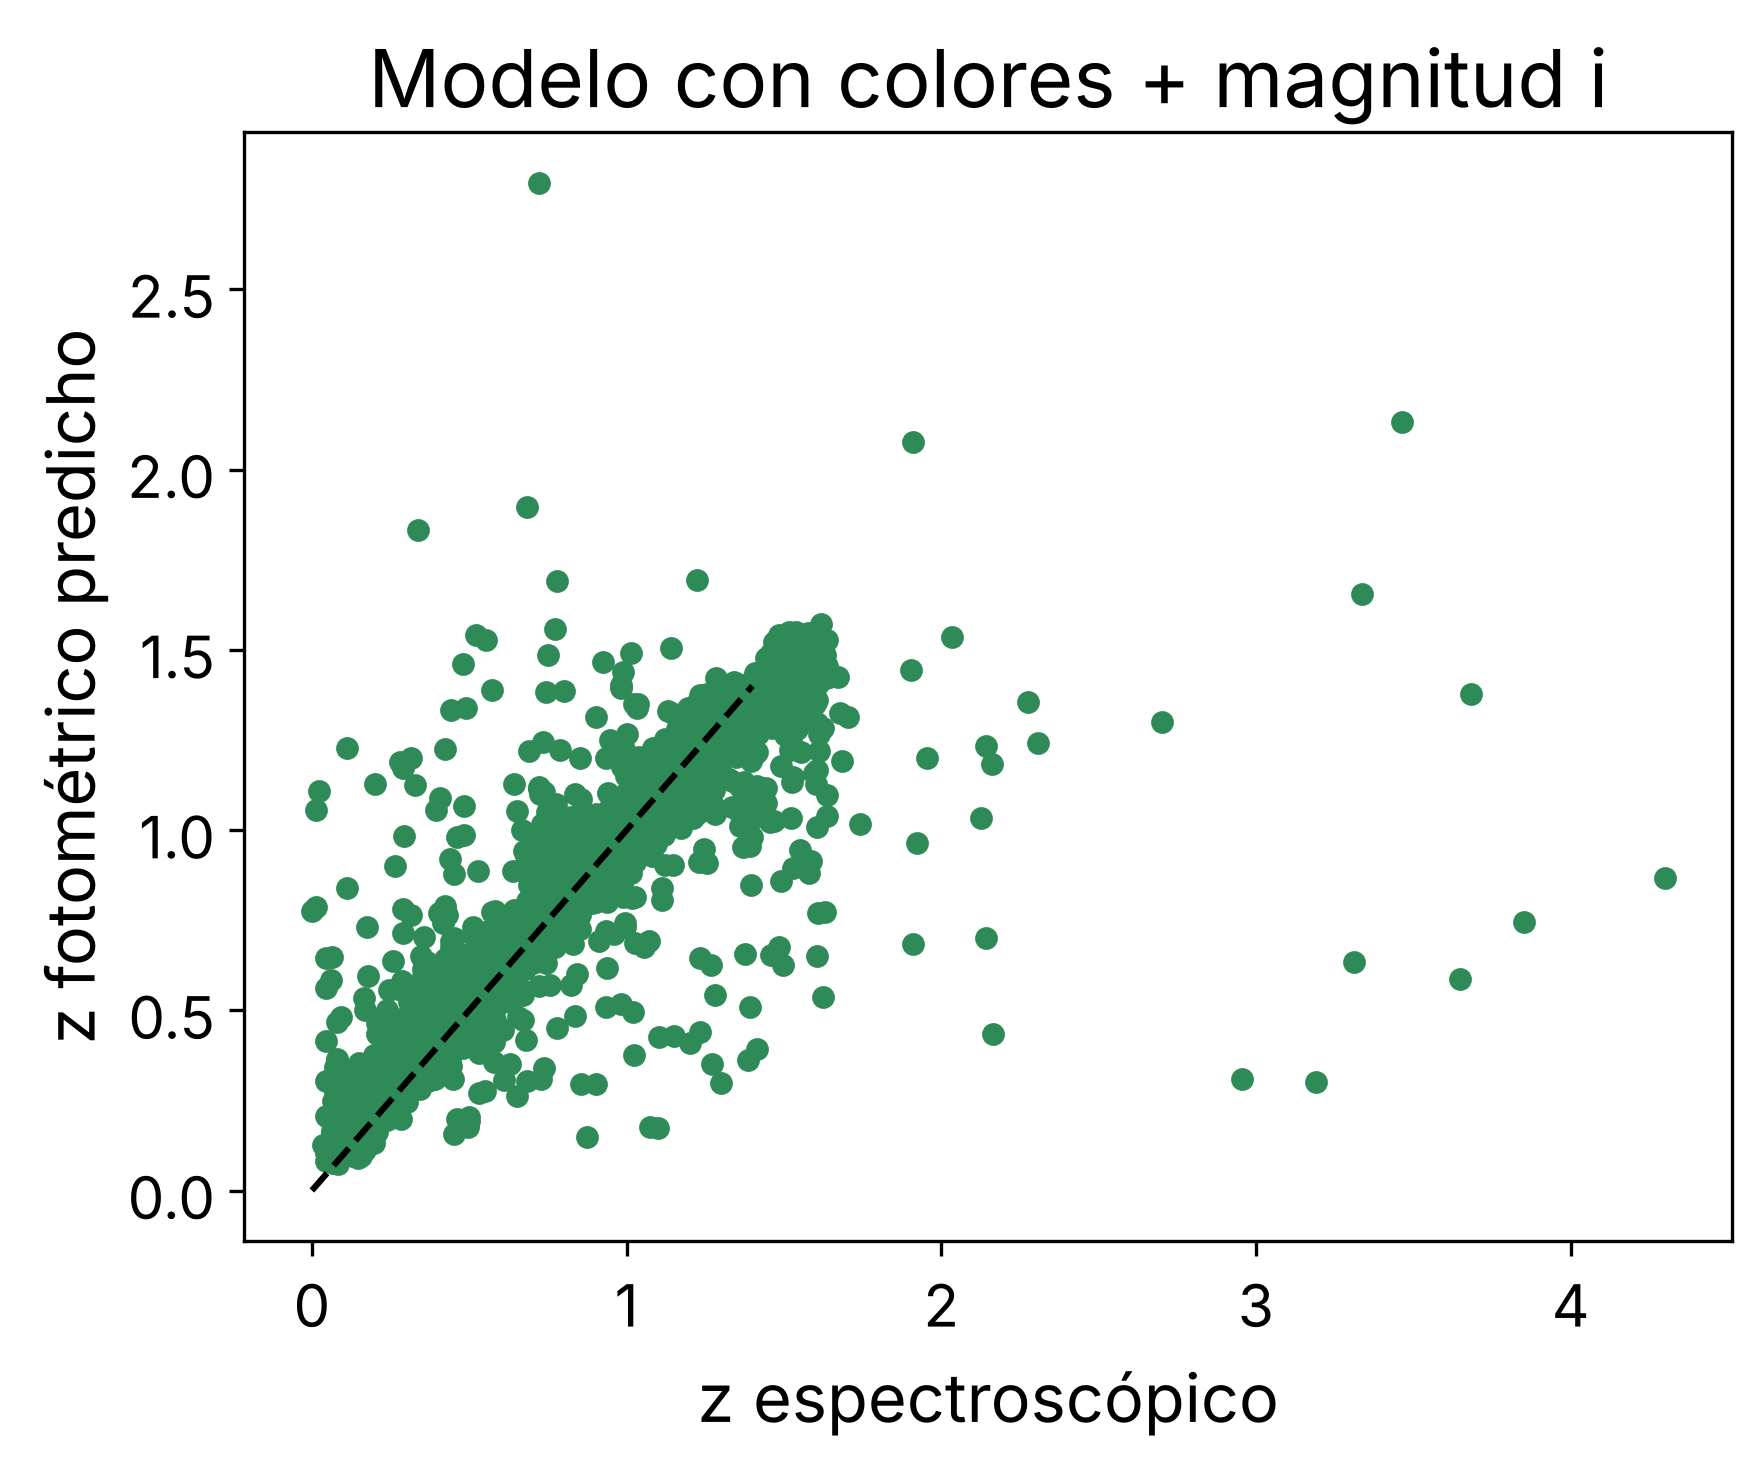

In [52]:
plt.scatter(target_colors, ypred_colors, s=20, c='seagreen')
plt.xlabel('z espectroscópico')
plt.ylabel('z fotométrico predicho')
plt.plot([0,1.4],[0,1.4],'k--')
plt.title('Modelo con colores + magnitud i')
plt.show()

### Resumen de resultados finales

| Modelo | R² test | η (outliers) | σ_NMAD |
|---|---|---|---|
| Benchmark inicial (6 mags, sin limpiar) | ~0.31 | ~25.6% | ~0.075 |
| Benchmark con datos limpios (6 mags) | ~0.75 | ~5.4% | ~0.037 |
| **Colores + magnitud i (datos limpios)** | **~0.81** | **~3.6%** | **~0.016** |
| Paper (CFHTLS Deep, MAG_APERCOR) | — | 4.7% | 0.018 |

El modelo final con colores no solo mejora frente a nuestros propios benchmarks, sino que iguala/supera levemente los valores reportados en el paper, validando la hipótesis de la Sección 7: los colores capturan mejor la información relevante para estimar z que las magnitudes absolutas.

## Resumen de la tarea

**Qué se hizo en cada sección:**
- **Carga de datos:** se leyó el FITS de DEEP2/Subaru (23822 objetos) a un DataFrame, corrigiendo el orden de bytes big-endian→little-endian.
- **Benchmark inicial:** Random Forest con las 6 magnitudes crudas (`*_apercor`) y target `zhelio`, sin limpieza de datos. R² test ~0.31, con brecha grande respecto a train (~0.88) → varianza alta, en parte por mediciones inválidas (-99/99) y objetos de mala calidad espectroscópica.
- **Métricas del paper:** se calcularon η (fracción de outliers) y σ_NMAD sobre las predicciones del benchmark inicial, bastante peores que lo reportado en el paper.
- **Optimización de hiperparámetros (GridSearchCV):** sobre un subsample de 5000 objetos, se barrieron `min_impurity_decrease`, `max_features`, `n_estimators`, `min_samples_split` y `max_leaf_nodes` (243 combinaciones × 5 folds). La mejora sobre el modelo default fue modesta, indicando que el cuello de botella principal no son los hiperparámetros.
- **Limpieza de datos:** se filtró por `zquality>=3`, `cfhtls_source==0` y se eliminaron mediciones inválidas (<-10 o >90), quedando 6307 objetos. Repitiendo el benchmark sobre estos datos limpios, el R² test subió a ~0.75 y η/NMAD bajaron fuertemente, confirmando que la calidad de los datos era el problema principal.
- **Mejora según Sección 7 del paper:** se construyó un modelo con 5 colores (u-g, g-r, r-i, i-z, z-y) + magnitud i, en vez de las 6 magnitudes absolutas. Este modelo final alcanza R² test ~0.81, η~3.55%, σ_NMAD~0.016, igualando/superando el valor reportado por el paper para fotometría CFHTLS Deep (η=4.7%, σ_NMAD=0.018).

**Puntos que deberías revisar:**
- En la celda de lectura del FITS se reemplazó `np.array(data[1].data).byteswap().newbyteorder()` por `arr.byteswap().view(arr.dtype.newbyteorder())`, porque `ndarray.newbyteorder()` fue eliminado en numpy 2.x. Es un cambio de compatibilidad, no de lógica (el resultado es idéntico).
- `RandomForestRegressor()` se usa sin `random_state` fijo en el notebook (no se puede cambiar esa celda), así que la reproducibilidad se logra fijando `np.random.seed(...)` justo antes de cada `fit`/`cross_validate`/`cross_val_predict` (el RF toma su aleatoriedad del generador global de numpy).
- En la celda de GridSearchCV, el objeto resultante se asigna a la variable `model` (no a un nombre nuevo), porque la celda siguiente ya escrita en el notebook usa `model.cv_results_`. Por eso, para el benchmark posterior con los datos limpios se usó una variable distinta (`benchmark_model`) y así no se perdió el objeto del grid search.
- La interpretación de "revise la sección 7 del paper" se investigó directamente en el paper (arXiv:1903.08174): la mejora identificada es usar colores + magnitud i en vez de magnitudes absolutas (no, por ejemplo, cambiar a `ExtraTreesRegressor`, que estaba importado pero sin usar).